In [ ]:
# importing necessary modules and libraries
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# reading csv file and storing dataset in df
df = pd.read_csv("/credit_default_classification.csv")

In [ ]:
# checking the dataset properties, null values, data types of attributes
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 257 entries, 0 to 256
Data columns (total 11 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   age                  257 non-null    float64
 1   loan_amount_k        257 non-null    float64
 2   credit_score         257 non-null    float64
 3   home_owner           257 non-null    object 
 4   num_open_accounts    257 non-null    float64
 5   income_k             257 non-null    float64
 6   loan_purpose         257 non-null    object 
 7   defaulted            257 non-null    float64
 8   customer             257 non-null    int64  
 9   months_since_delinq  257 non-null    float64
 10  credit_score_dup     257 non-null    float64
dtypes: float64(8), int64(1), object(2)
memory usage: 22.2+ KB


In [ ]:
# to check number of null values present in each attribute
df.isnull().sum()

,0
age,0
loan_amount_k,0
credit_score,0
home_owner,0
num_open_accounts,0
income_k,0
loan_purpose,0
defaulted,0
customer,0
months_since_delinq,0


In [ ]:
# missing handling values by using statistical measures using fillna function

# listed all the missing valued columns which can be filled by mean
mean_columns = ["loan_amount_k","credit_score","income_k","months_since_delinq","credit_score_dup"]

# filling the columns with mean
df[mean_columns] = df[mean_columns].fillna(df[mean_columns].mean())

# filling age and number of accounts columns with median
df["age"] = df["age"].fillna(df["age"].median())
df["num_open_accounts"] = df["num_open_accounts"].fillna(df["num_open_accounts"].median())

# since home owner and loan purpose are categorical data it can be filled with mode, filled using mode function
df["home_owner"] = df["home_owner"].fillna(df["home_owner"].mode()[0])
df["loan_purpose"] = df["loan_purpose"].fillna(df["loan_purpose"].mode()[0])

# filling the missing values in defaulted column using forward fill function
df["defaulted"].ffill()

# dropped the duplicate columns and also customer column to handle the inconsistencies
df = df.drop(columns = ["customer","credit_score_dup"])

# inserting new customer column and given each one a unique customer id using np.arange() function
df["customer"] = np.arange(1,258)



In [ ]:
# handling inconsistenceis of data like spelling mistakes which are solved using replace function

# handling errors of loan_purpose using replace function
df["loan_purpose"].replace(["Debt cnsolidation",'Debt consolidtion',"Debt consolidation","Debt consolidition","Dbt consolidation","Debt consolidaton","DEBT CONSOLIDATION"],"Debt Consolidation",inplace = True)
df["loan_purpose"].replace(["Home improvemnt","Home improvement","Home imprvement","HOME IMPROVEMENT","Home imrovement","Hme improvement","Hoe improvement","ome improvement","Hom improvement"],"Home Improvement",inplace = True)
df["loan_purpose"].replace(["Business","Busines","BUSINESS","Buiness","usiness","Businss","Busness","Busiess","Bsiness"],"Business",inplace = True)
df["loan_purpose"].replace(["Cr","CAR","ar"],"Car",inplace = True)
df["loan_purpose"].replace(["EDUCATION","Educatin","ducation","Eduction","Educaion","Educatio","Edcation","Eucation"],"Education",inplace = True)

#  handling home_owner errors using replace function
df["home_owner"].replace(["Ye","Ys","es","YES"],"Yes",inplace = True)
df["home_owner"].replace(["NO","N",'o'],"No",inplace = True)

# handling the outliers problem of negative values solved using abs function and rounded the values to 2 decimal points
df["income_k"] = df["income_k"].abs().round(2)

# rounded of all the credit_score column values to 0 decimal points
df["credit_score"] = df["credit_score"].round(0)

/tmp/ipykernel_1032/1807164106.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df["loan_purpose"].replace(["Debt cnsolidation",'Debt consolidtion',"Debt consolidation","Debt consolidition","Dbt consolidation","Debt consolidaton","DEBT CONSOLIDATION"],"Debt Consolidation",inplace = True)
/tmp/ipykernel_1032/1807164106.py:7: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never wo

In [ ]:
# testing the unique values while working with inconsistencies
df["credit_score"].unique()

array([792., 637., 365., 721., 839., 616., 374., 358., 685., 314., 530.,
       498., 653., 566., 461., 770., 830., 647., 446., 673., 715., 793.,
       555., 402., 420., 718., 649., 341., 666., 328., 313., 784., 488.,
       594., 482., 847., 336., 458., 382., 321., 431., 764., 755., 601.,
       694., 419., 545., 337., 544., 320., 409., 693., 709., 627., 589.,
       810., 660., 705., 519., 406., 585., 307., 380., 407., 645., 499.,
       338., 606., 303., 376., 767., 478., 575., 451., 463., 677., 688.,
       605., 371., 518., 472., 571., 568., 319., 802., 728., 464., 609.,
       817., 738., 562., 524., 557., 533., 635., 708., 323., 570., 394.,
       441., 573., 507., 595., 587., 423., 582., 479., 396., 490., 373.,
       796., 783., 415., 834., 397., 706., 612., 447., 641., 794., 322.,
       521., 377., 621., 540., 317., 742., 576., 723., 775., 326., 813.,
       763., 662., 682., 824., 681., 483., 493., 761., 529., 788., 724.,
       674., 340., 559., 740., 383., 345., 739., 81

***1. UNIVARIATE ANALYSIS***

Text(0.5, 0, 'age')

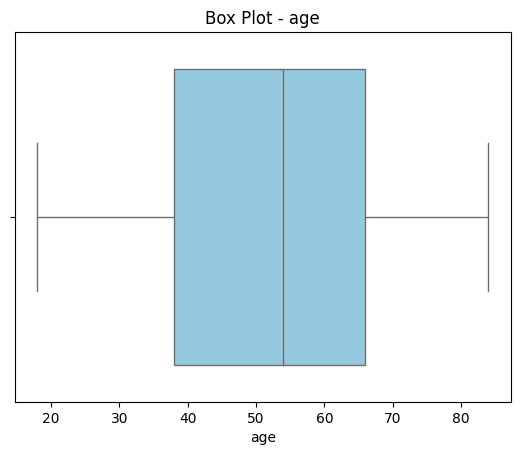

In [ ]:
# BOXPLOT graph to display the analysis of age using seaborn module
sns.boxplot(x=df["age"], color='skyblue')
plt.title(f'Box Plot - age')
plt.xlabel("age")

<Axes: xlabel='credit_score', ylabel='Count'>

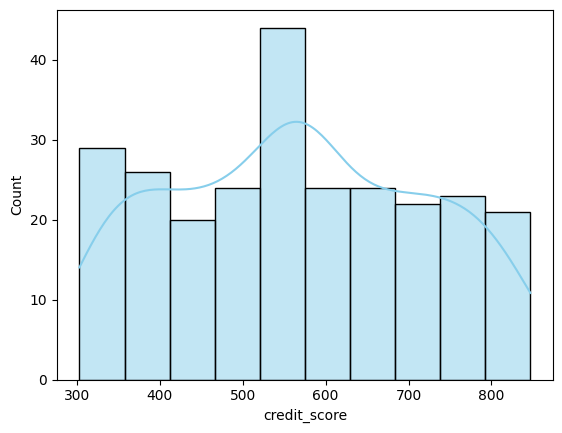

In [ ]:
# distribution plot to display the creditscore
sns.histplot(df["credit_score"], kde=True, color='skyblue')

Text(0, 0.5, 'Count')

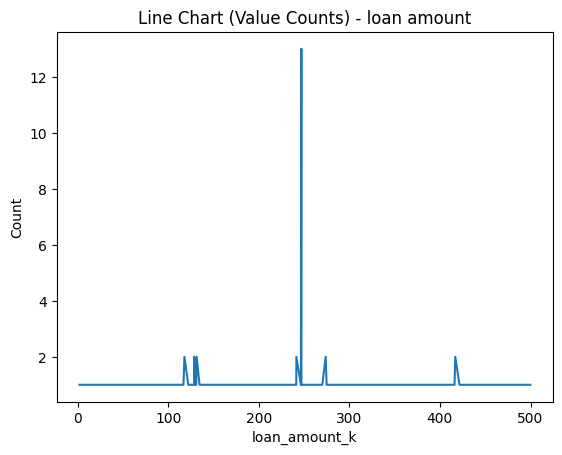

In [ ]:
# visualizing loan_amount_k using lineplot
sns.lineplot(data=df["loan_amount_k"].value_counts().sort_index())
plt.title(f'Line Chart (Value Counts) - loan amount')
plt.xlabel("loan_amount_k")
plt.ylabel('Count')

### 2. Bivariate Analysis


/tmp/ipykernel_1032/345992466.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, y='loan_purpose', palette='pastel')


<Axes: xlabel='count', ylabel='loan_purpose'>

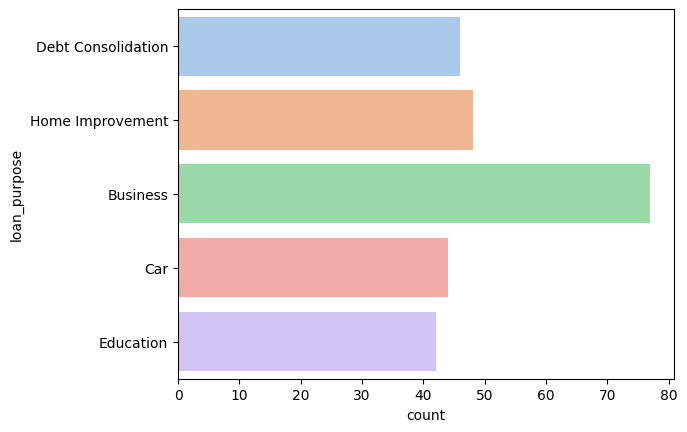

In [ ]:
# visualizing the loan_purpose column with countplot using seaborn module
sns.countplot(data=df, y='loan_purpose', palette='pastel')

/tmp/ipykernel_1032/3588807036.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='defaulted', y='credit_score',  palette='Set2')


<Axes: xlabel='defaulted', ylabel='credit_score'>

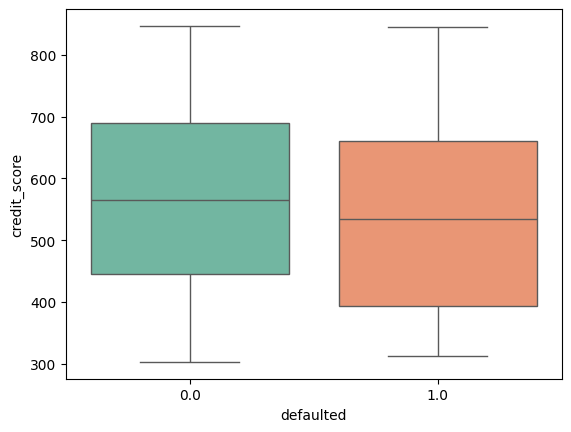

In [ ]:
# visualizing the defaulted and credit_score using box plot
sns.boxplot(data=df, x='defaulted', y='credit_score',  palette='Set2')


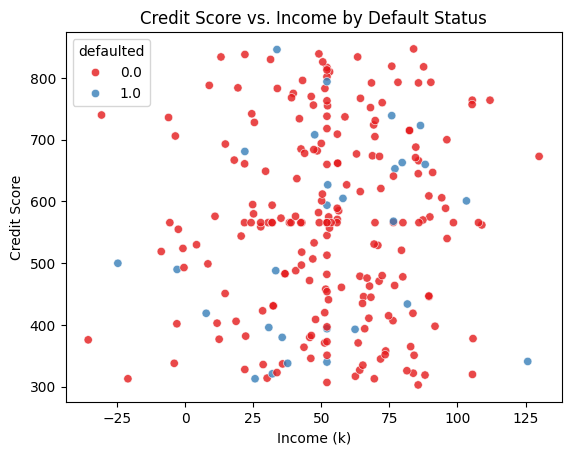

In [ ]:
# Scatter plot exploring Credit Score vs. Income colored by Default status

sns.scatterplot(data=df, x='income_k', y='credit_score', hue='defaulted', palette='Set1', alpha=0.8)
plt.title('Credit Score vs. Income by Default Status')
plt.xlabel('Income (k)')
plt.ylabel('Credit Score')
plt.show()

***3. Multivariate Analysis***

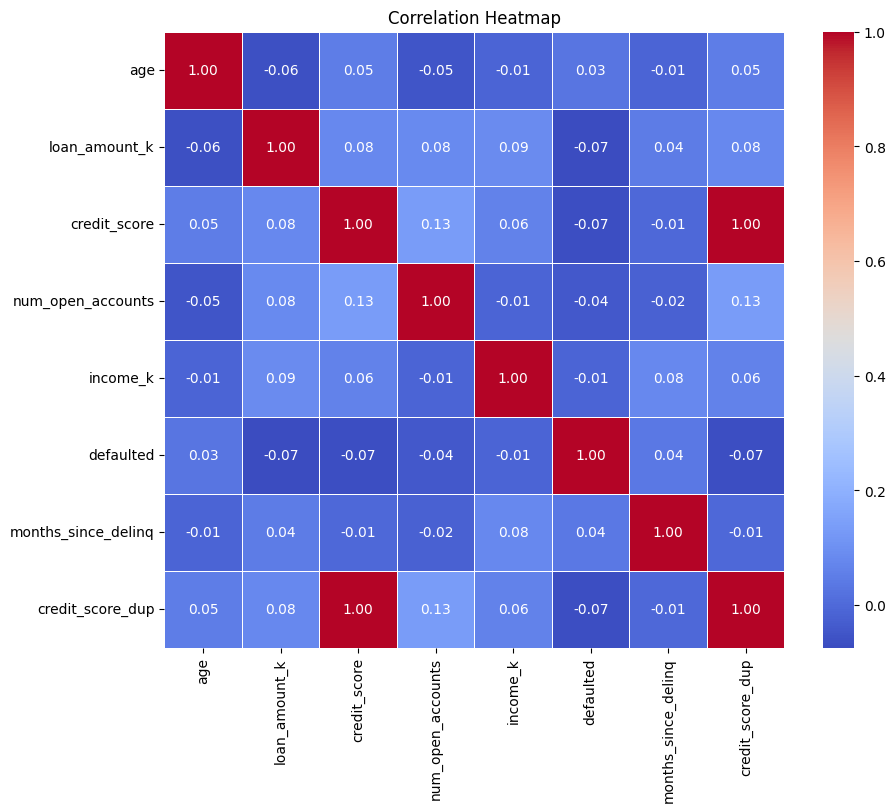

In [ ]:
# Correlation Heatmap of numerical features
plt.figure(figsize=(10, 8))
numeric_df = df.select_dtypes(include=[np.number]).drop(columns=['customer'])
correlation_matrix = numeric_df.corr()
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Correlation Heatmap')
plt.show()

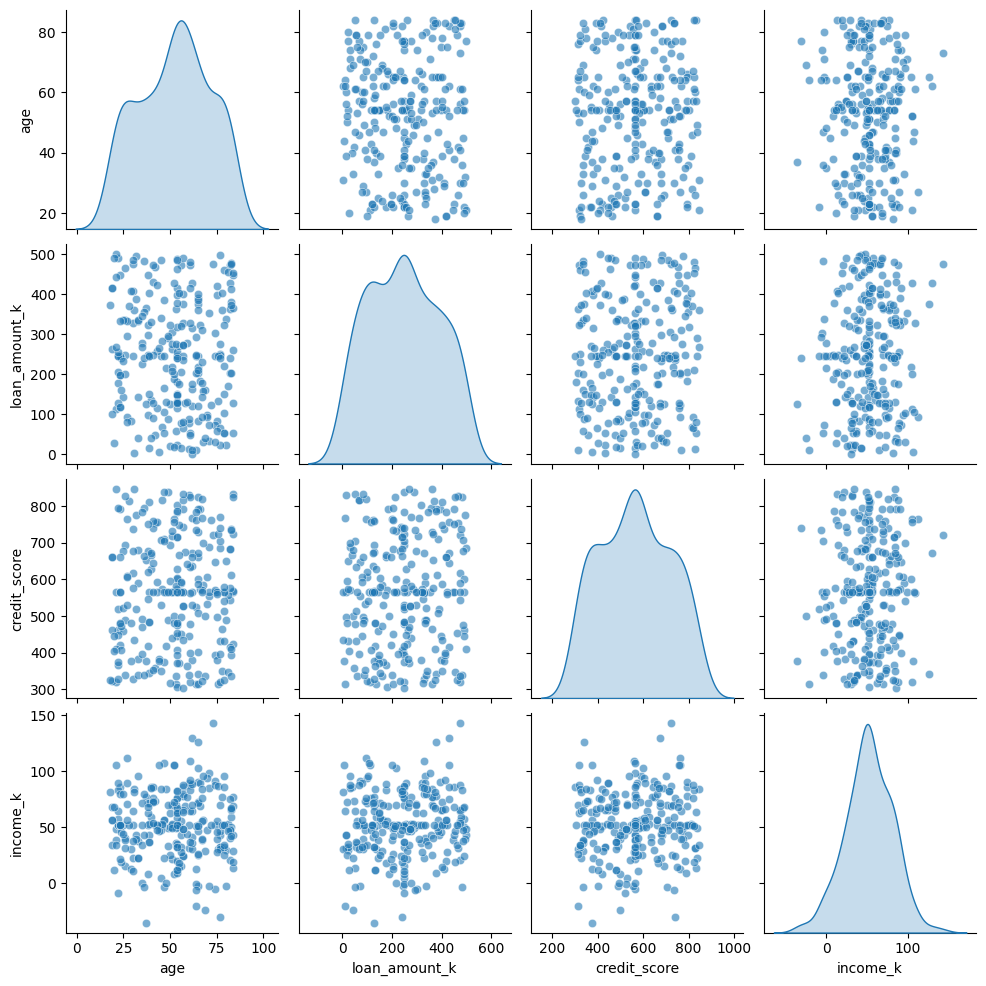

In [ ]:
# pair plot for numerical columns using seaborn module
num_cols = ['age', 'loan_amount_k', 'credit_score', 'income_k']
sns.pairplot(df[num_cols], diag_kind='kde', plot_kws={'alpha': 0.6})

# Credit Default Classification Dataset Analysis Report

## 1. Executive Summary
The Credit Default Classification dataset contains **257 records and 9 cleaned columns** (after removing duplicate columns). It includes critical financial and demographic details of borrowers, such as age, credit score, income, loan amount, homeownership status, and loan purpose.

This analysis aims to explore the characteristics of the borrowers and visualize key patterns to understand what profiles are linked with loan defaults.

## 2. Data Quality & Preprocessing Assessment
The dataset underwent thorough preprocessing to correct structural issues and missing data before visualization:
- **Missing Value Treatment:** Continuous columns such as age, loan_amount_k, and credit_score were filled using appropriate statistics (mean or median). Categorical attributes like home_owner and loan_purpose were imputed using their mode. The missing entries in the target column defaulted were filled using forward fill.
- **Inconsistency Correction:** Text labels inside loan_purpose and home_owned were mapped to clean, unified categories to resolve spelling inconsistencies. Outlier and invalid negative values in income_k were rectified using absolute mapping (abs()).
- **Feature Reduction:** Unnecessary or redundant columns such as credit_score_dup and the noisy customer index were dropped. A clean incremental ID sequence was reintroduced.

## 3. Univariate Analysis (Individual Attributes)
We assessed features independently to determine distributions:
- **Age Distribution:** Represented using a Seaborn Box Plot, showing that our borrowers' ages range from late 10s to mid-80s, with a median age of around 54 years.
- **Credit Score Distribution:** Visualized via a histogram with a KDE fit, indicating multiple peaks (multimodal distribution) spanning from roughly 300 to 850.
- **Loan Amount (k):** Charted using a line plot of value counts to spot frequency spikes, showing a prominent concentration of loans requested around the $250K mark.
- **Loan Purpose:** A count plot shows that **Business** loans are the most widely requested, followed by Home Improvement, Debt Consolidation, Car, and Education.

## 4. Bivariate & Multivariate Analysis
We explored relationships between multiple features to extract key insights:
- **Default Status vs. Credit Score:** The bivariate box plot reveals that borrowers who defaulted (defaulted = 1.0) generally tend to possess a lower median credit score compared to non-defaulters (defaulted = 0.0).
- **Credit Score vs. Income (by Default Status):** The scatter plot shows that defaults occur across various income thresholds, but they are visually concentrated around lower credit score levels.
- **Correlation & Pair Relationships:**
  - The pair plot demonstrates low linear dependency among features like age, income, and loan amount, highlighting highly distributed data scatter.
  - The correlation heatmap mathematically confirms weak linear correlations between almost all numerical features (ranging from -0.06 to +0.13), implying that predicting defaults will likely require non-linear machine learning models (e.g., ensemble trees).